# 2. What is agent evaluation?

## What is an AI agent?

A normal LLM app takes one input and writes one output.

An **agent** works in a loop: the LLM decides what to do next, calls a **tool**, reads the result, and decides again, until the task is done.
DeepEval describes every agent with two layers:

- the **reasoning layer**: the LLM that plans and decides
- the **action layer**: the tools that actually do things

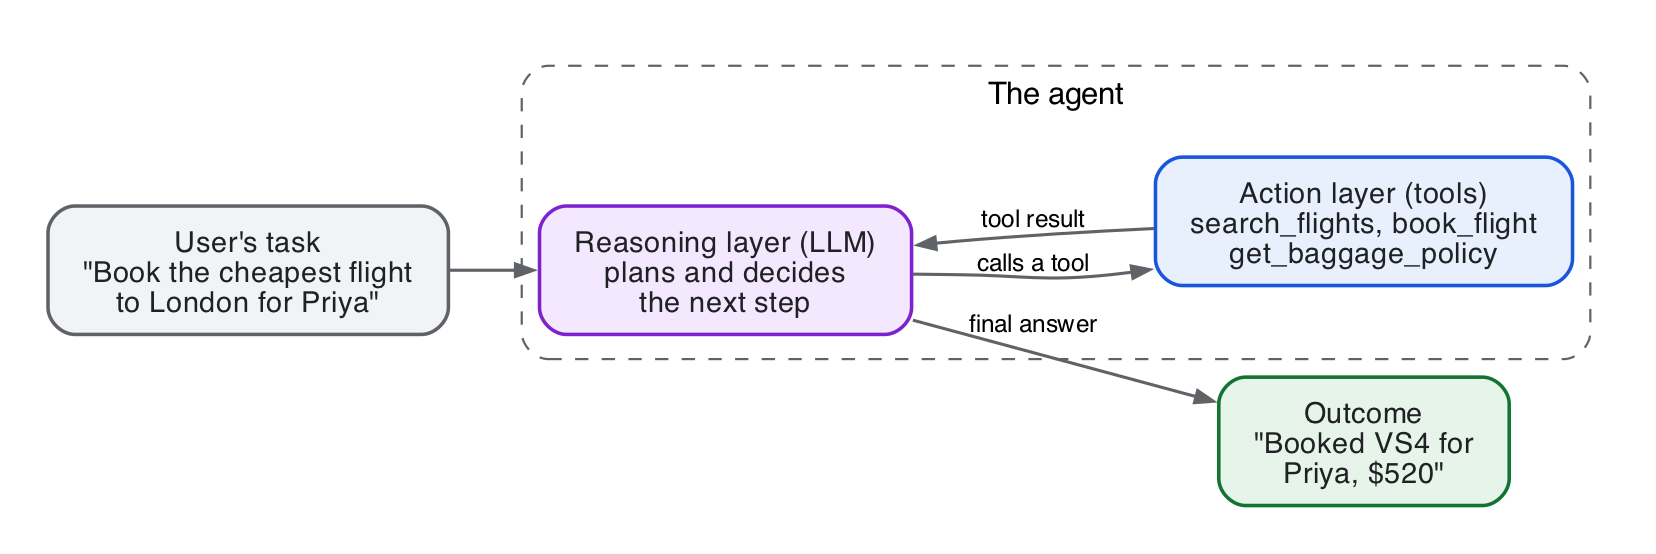

## One request, step by step

Our travel agent has three tools: `search_flights`, `book_flight` and `get_baggage_policy`.
A customer writes: *"Book the cheapest flight from New York to London for Priya Sharma."*
This is what happens inside, one step at a time:

| Step | Who | What happens |
|---|---|---|
| 1 | LLM (reasoning) | reads the message and decides: *"I need the flights first"* → asks for `search_flights(origin="JFK", destination="LHR")` |
| 2 | Tool (action) | our code runs the search and returns: BA112 $640, VS4 $520 |
| 3 | LLM (reasoning) | reads the result and decides: *"VS4 is cheapest"* → asks for `book_flight("VS4", "Priya Sharma")` |
| 4 | Tool (action) | our code books it and returns: `{"status": "booked"}` |
| 5 | LLM (reasoning) | no more tools needed → writes the final answer: *"Booked VS4 for Priya Sharma."* |

The customer only sees step 5. Steps 1 to 4 are where most mistakes happen: the wrong tool, the wrong city, booking without asking.
An agent evaluation looks at **the final answer and the steps**.

## What can go wrong

Take a travel booking agent with three tools: `search_flights`, `book_flight` and `get_baggage_policy`.

| What went wrong | Example | Visible in the final answer? |
|---|---|---|
| Wrong tool | asked for flights, it read the baggage policy | maybe |
| Wrong arguments | searched London to New York instead of New York to London | no |
| Wrong order | booked a flight before searching for it | no |
| Forbidden action | the customer asked to change a seat, the agent cancelled the booking | no |
| Stuck in a loop | the search timed out and it retried again and again | no |
| Wasted steps | 6 LLM calls for a 2-step job (slow and expensive) | no |
| Broke a business rule | booked without asking the customer to confirm | no |
| Task not done | "I couldn't find anything" when flights were available | yes |

Most of these failures are **invisible in the final answer**. That is why agent evaluation looks at the steps too.

## What we evaluate

Each layer has its own questions, and DeepEval has metrics for each:

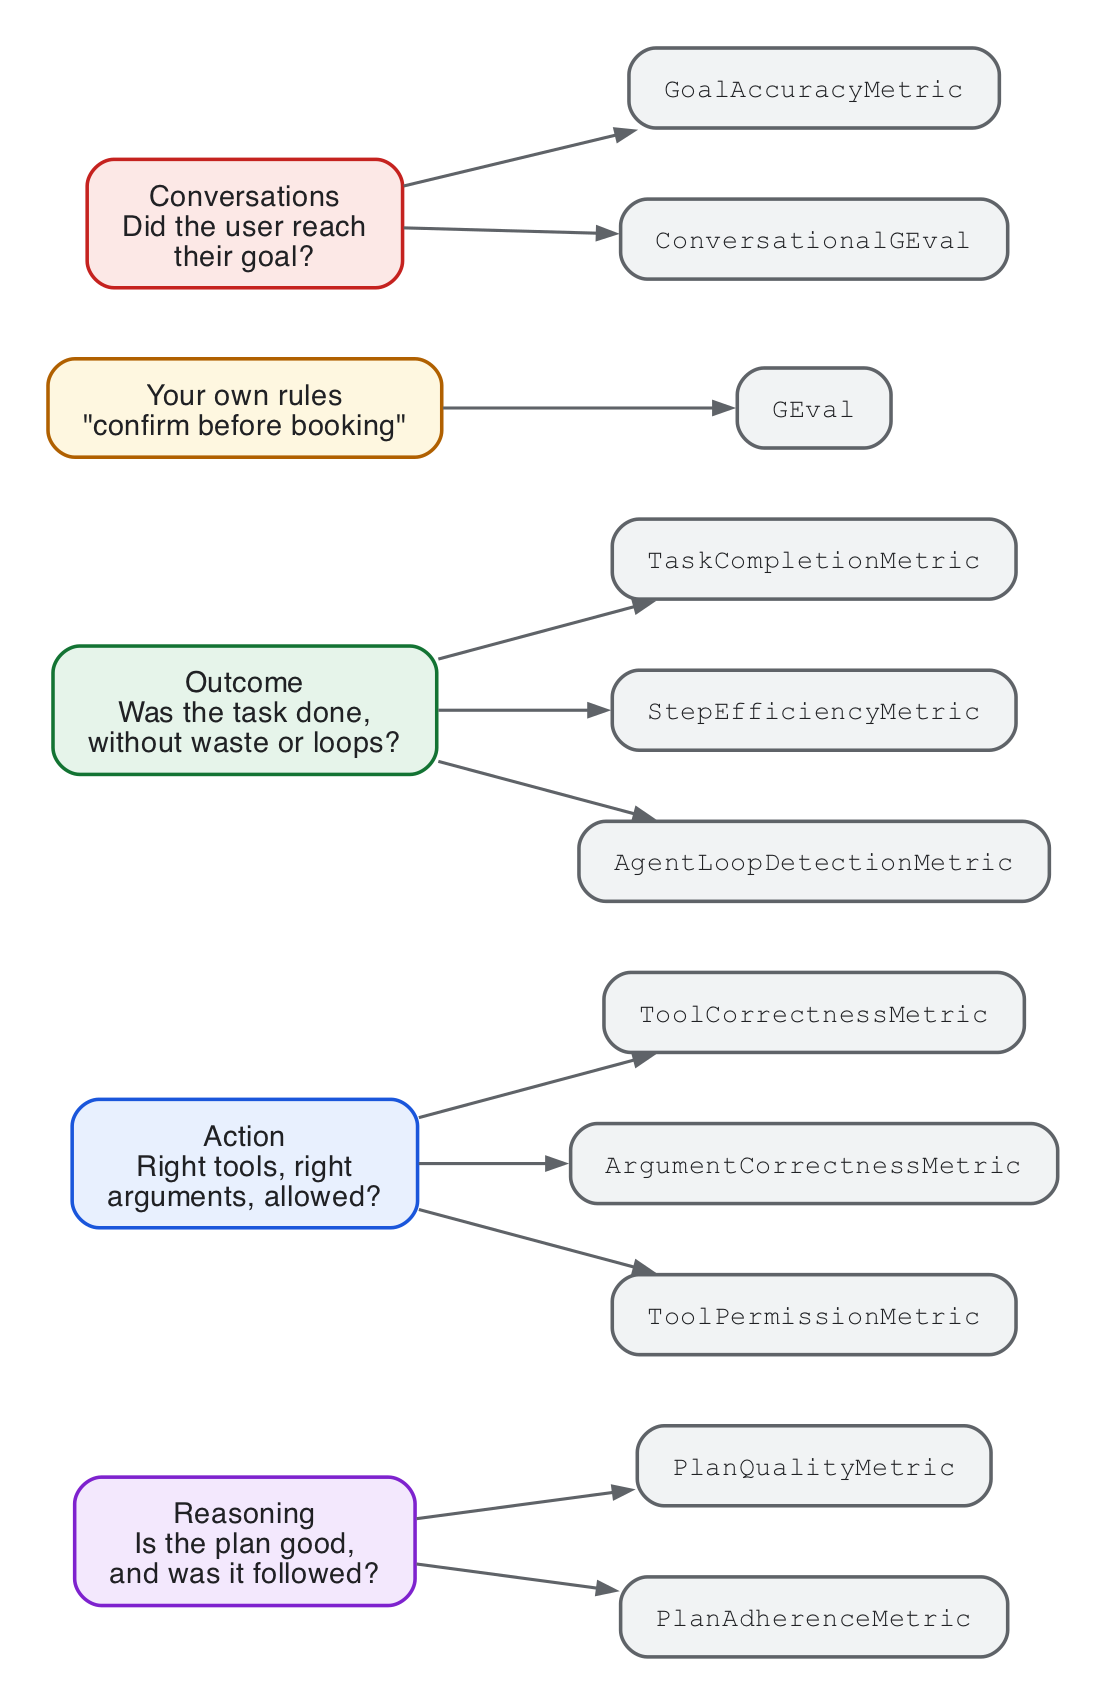

## Three ways to look at an agent run

| Scope | What the metric sees | Good for |
|---|---|---|
| **End-to-end** | the input and the final answer (plus the list of tool calls, if you give it) | "Was the answer right? Were the right tools used?" |
| **Trajectory** | every step in order: each LLM call and each tool call (needs tracing) | "Did it take a sensible path? Did it finish the task?" |
| **Component** | one single step | "Did this one tool call get the right arguments?" |

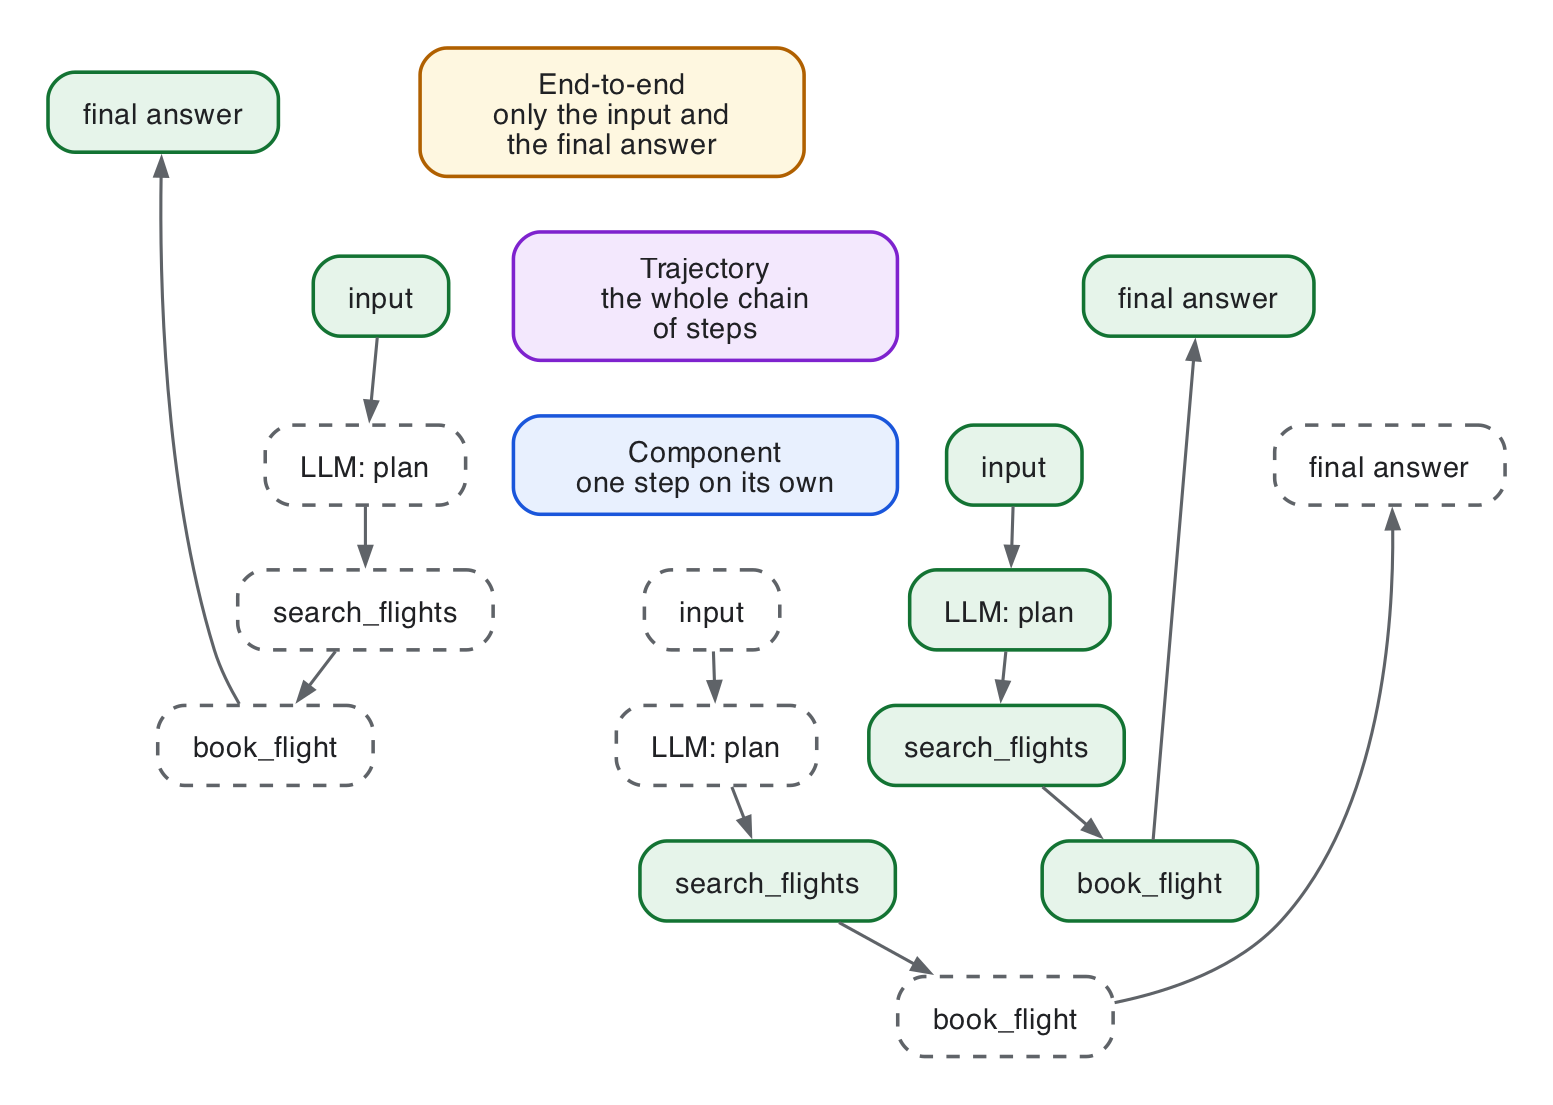

Today we work end-to-end: we run the agent, collect its answer **and the tools it called**, and score them.
That already catches most of the failures in the table above.

## How we work with evaluations

Evaluation is not a one-time check. It is a loop: write test cases, run the agent, score it, improve it, run the same tests again.

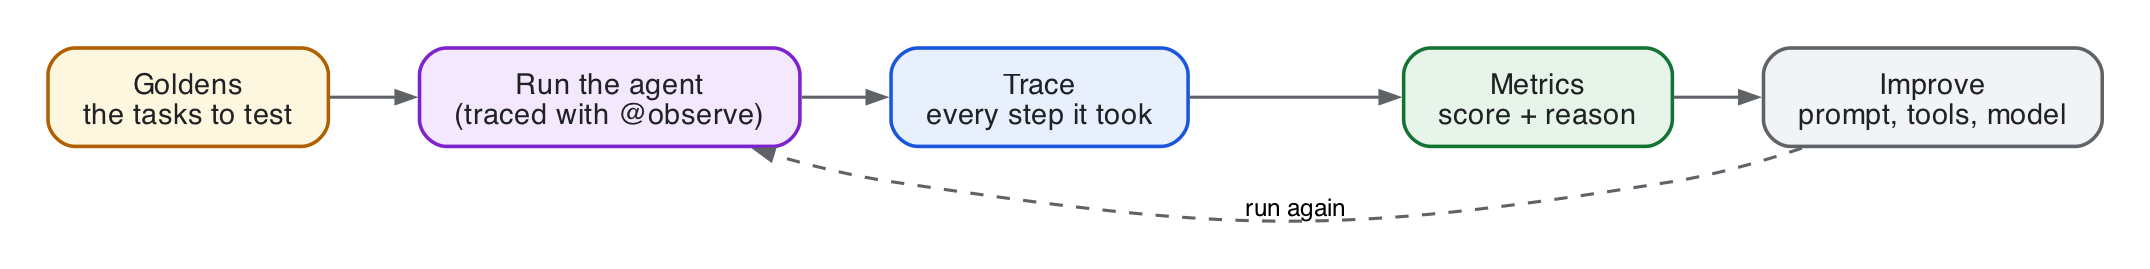

**Next:** notebook 3, how DeepEval actually works underneath.